#Introduction to Linear Algebra and the world of probablitites

In this work-sheet, we shall do two activities. First of all we shall check the power of SVD. Then we shall check how may we generate data from an arbitrary distribution (given that we have the ability to generate data from a uniform distribution).

##Singular Value Decomposition
Lets load an image and try to do it's SVD.

Please note the way to access an image from your Google drive. Change the code accordingly (and load an image in your Google drive) to access to your own image!

Mark that we shall be using PIL's Image library, a useful set of powerful algorithms for image processing.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import time

from PIL import Image

In [ ]:
# Load the Drive helper and mount
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Lets load the image and convert that to a gray-scale version (so that we can treat it just like a 2D matrix).
####**What will happen if its not gray-scale?**
If the image is not grayscale, each pixel has three color channels (RGB) instead of one intensity value, so we would need to process each channel separately or use a 3D array instead of a 2D matrix.

#### **Mark how we have used the command $matrix$ to generate a matrix from the image!**
This command converts the pixel values into a 2D matrix, allowing us to perform mathematical operations on it (SVD).

In [ ]:
img = Image.open("/content/drive/My Drive/ML4Space/random.JPG")
imggray = img.convert('L')

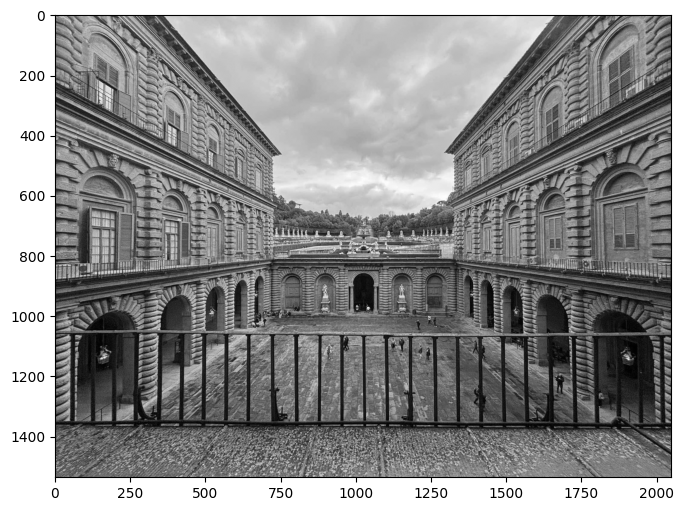

In [ ]:
imgmat = np.array(list(imggray.getdata(band=0)), float)
imgmat.shape = (imggray.size[1], imggray.size[0])
imgmat = np.matrix(imgmat)
plt.figure(figsize=(9,6))
plt.imshow(imgmat, cmap='gray')

###SVD

We can directly use the $svd$ command from Numpy to operate SVD on the matrix.

Lets first check how the image will look if we only use a single vector to reconstruct the image.

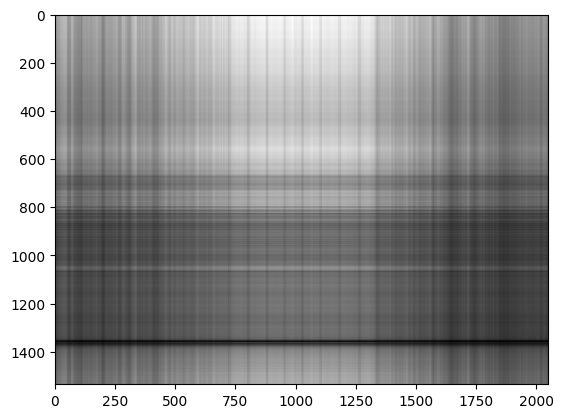

In [ ]:
U, sigma, V = np.linalg.svd(imgmat)
reconstimg = np.matrix(U[:, :1]) * np.diag(sigma[:1]) * np.matrix(V[:1, :])
plt.imshow(reconstimg, cmap='gray');


Now lets check how does the sigma vector look like.

#### **What do you observe?**
The singular values decrease quickly, which means that most of the important information is stored in the first few components.

#### **How many vectors can we use to get a decent reconstruction of the image?**

After testing, ~50–70 components seem to be enough to get a decent reconstruction while keeping most of the important visual information. The exact number depends on the complexity of the image.

#### **What will happen if we omit the first 1–2 vectors (corresponding to the largest eigen values)?**

The reconstructed image loses important information, especially its overall structure and large-scale brightness patterns. It becomes less recognizable because the largest singular values carry the most information about the original image.

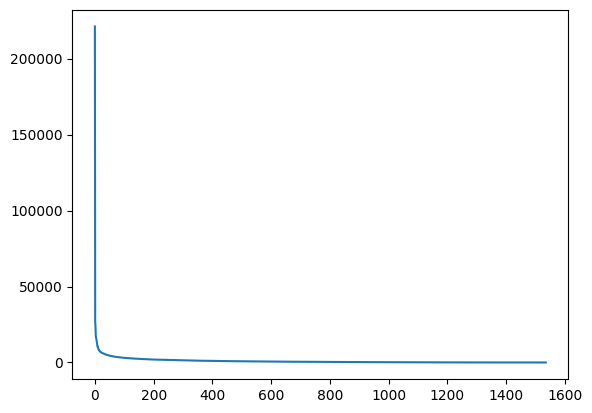

In [ ]:
U.shape
sigma.shape
plt.plot(sigma)

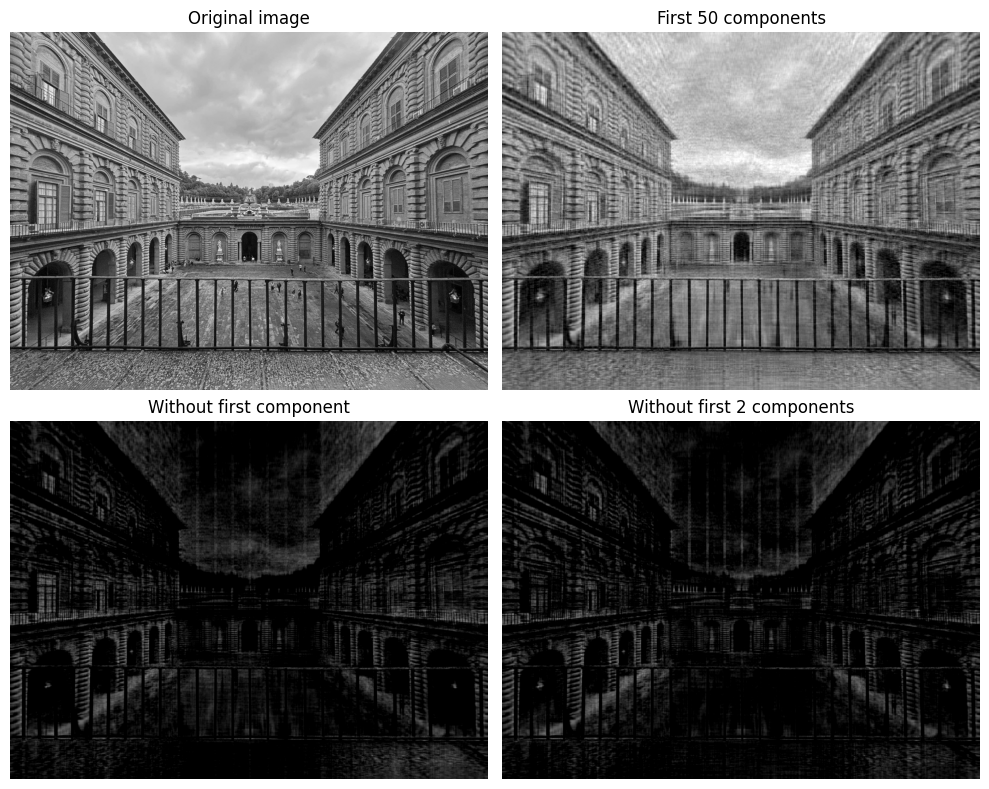

In [ ]:

k = 50 #num of components used for reconstruction

original = np.asarray(imgmat)

reconstruction_50 = (
    U[:, :k] @ np.diag(sigma[:k]) @ V[:k, :]
)

reconstruction_without_1 = (
    U[:, 1:k] @ np.diag(sigma[1:k]) @ V[1:k, :]
)

reconstruction_without_2 = (
    U[:, 2:k] @ np.diag(sigma[2:k]) @ V[2:k, :]
)

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

images = [
    (original, "Original image"),
    (reconstruction_50, "First 50 components"),
    (reconstruction_without_1, "Without first component"),
    (reconstruction_without_2, "Without first 2 components")
]

for ax, (image, title) in zip(axes.flatten(), images):
    ax.imshow(image, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis('off')

plt.tight_layout()
plt.show()


# Satellite Images

Urban: image size = (1856, 2442)
Forest: image size = (928, 1221)
Ocean: image size = (1899, 2500)


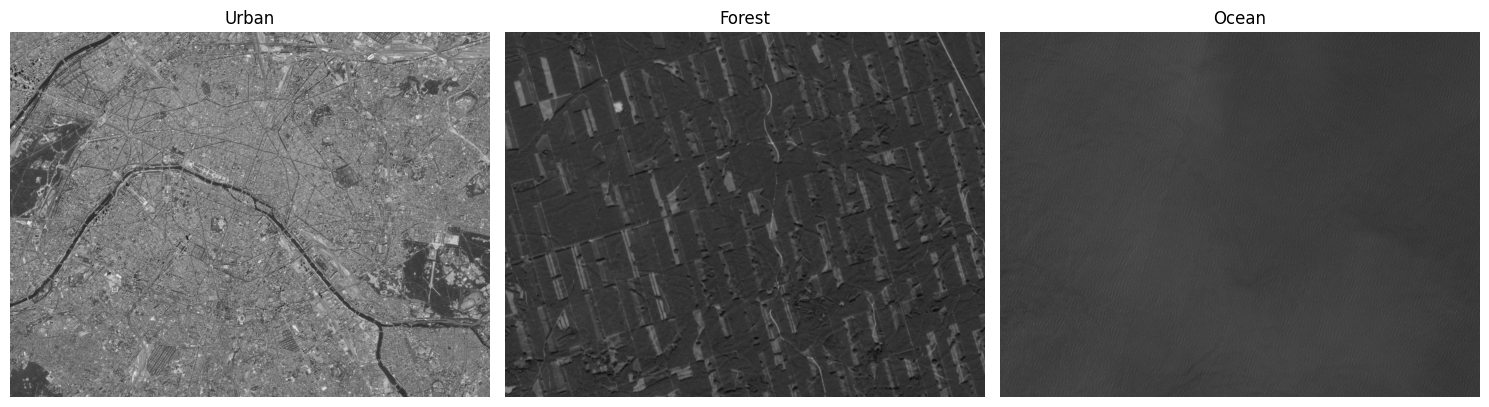

In [ ]:
image_paths = {
    "Urban": "/content/drive/MyDrive/ML4Space/urban.jpg",
    "Forest": "/content/drive/MyDrive/ML4Space/forest.jpg",
    "Ocean": "/content/drive/MyDrive/ML4Space/ocean.jpg"
}

images = {}

for name, path in image_paths.items():
    img = Image.open(path).convert('L')
    imgmat = np.array(img, dtype=float)
    images[name] = imgmat

    print(f"{name}: image size = {imgmat.shape}")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (name, img) in zip(axes, images.items()):
    ax.imshow(img, cmap='gray', vmin=0, vmax=255)
    ax.set_title(name)
    ax.axis('off')

plt.tight_layout()
plt.show()


## SVD
Here, we perform the SVD decomposition separately for each image and store the results in a dictionary so we can use them later.

In [ ]:
svd_results = {}

for name, img in images.items():
    U, sigma, Vh = np.linalg.svd(img, full_matrices=False)

    svd_results[name] = {
        "U": U,
        "sigma": sigma,
        "Vh": Vh
    }

    print(f"{name}: SVD completed")
    print(f"Number of singular values: {len(sigma)}")


Urban: SVD completed
Number of singular values: 1856
Forest: SVD completed
Number of singular values: 928
Ocean: SVD completed
Number of singular values: 1899


## Singular values
In addition, we use a logarithmic scale to better visualize the decline in value

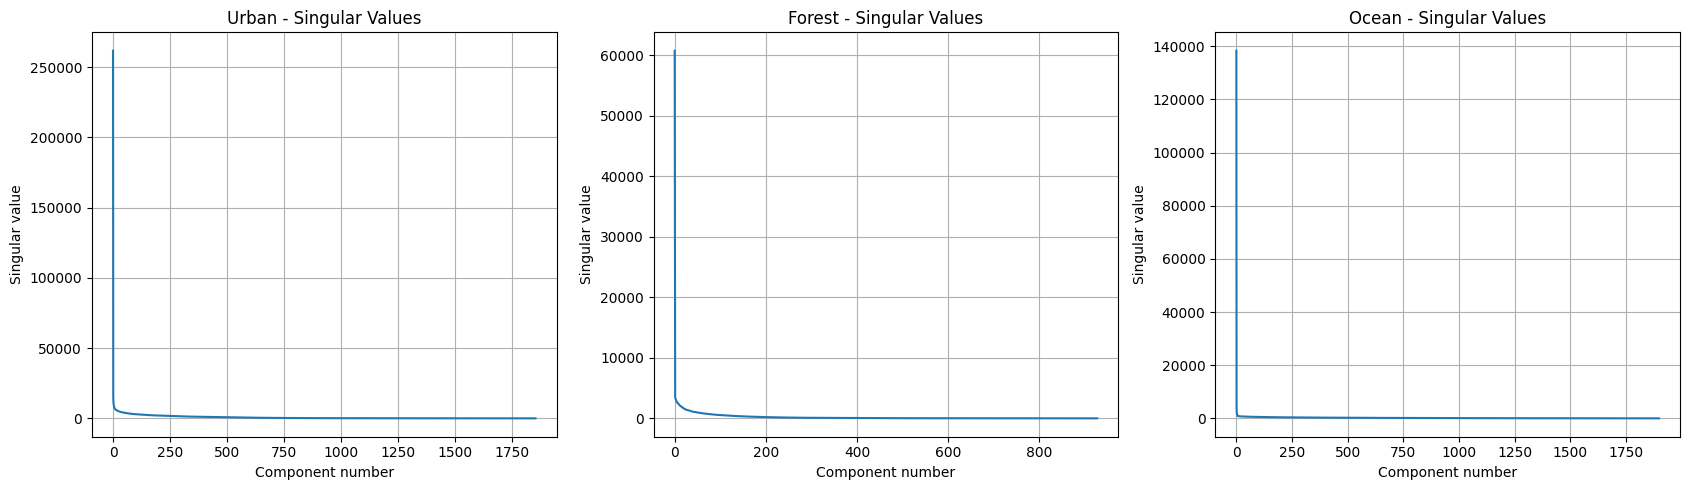

In [ ]:

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (name, result) in zip(axes, svd_results.items()):
    sigma = result["sigma"]

    ax.plot(sigma)
    ax.set_title(f"{name} - Singular Values")
    ax.set_xlabel("Component number")
    ax.set_ylabel("Singular value")
    ax.grid(True)

plt.tight_layout()
plt.show()


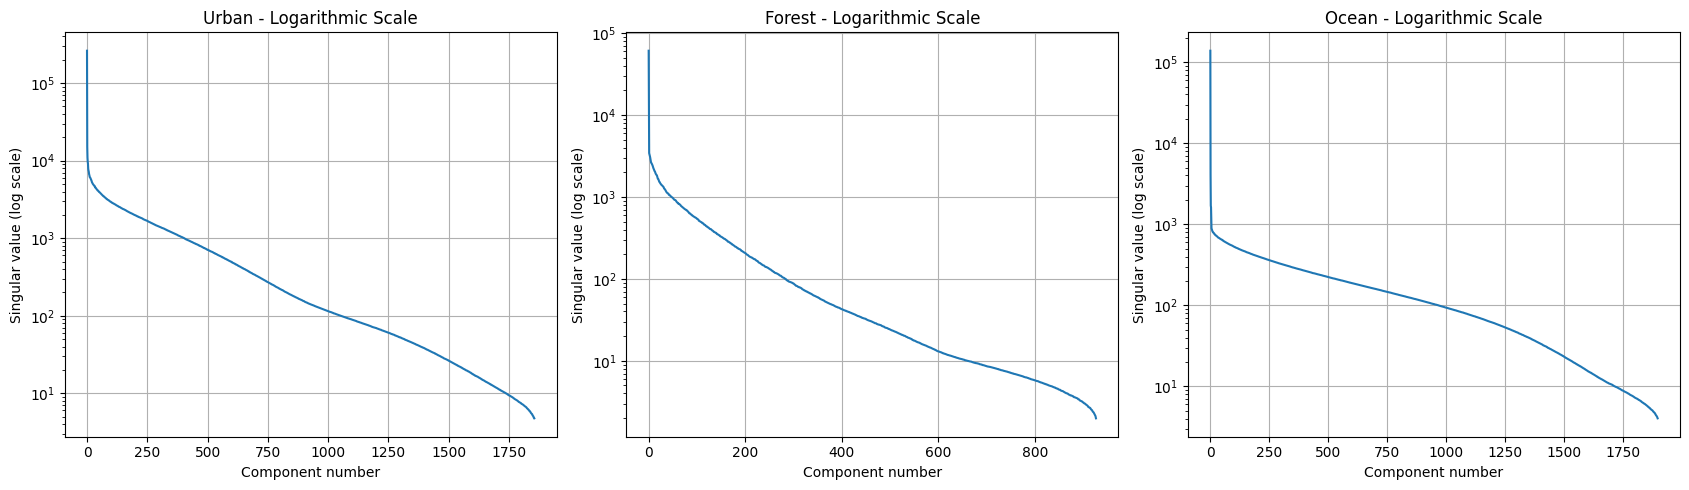

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (name, result) in zip(axes, svd_results.items()):
    ax.semilogy(result["sigma"])
    ax.set_title(f"{name} - Logarithmic Scale")
    ax.set_xlabel("Component number")
    ax.set_ylabel("Singular value (log scale)")
    ax.grid(True)

plt.tight_layout()
plt.show()


## Comparing images using different numbers of components

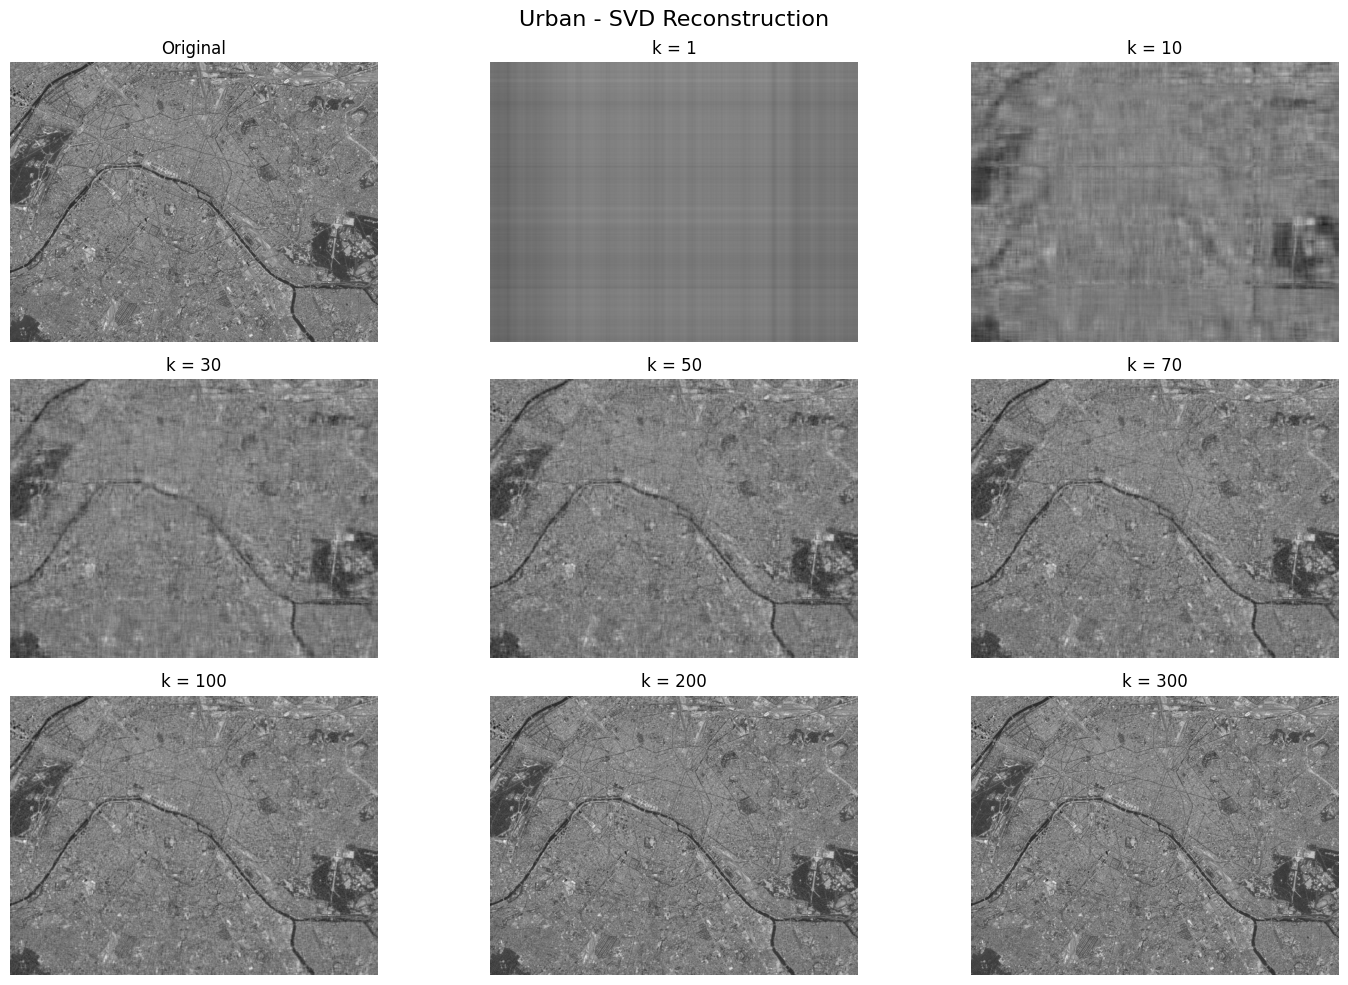

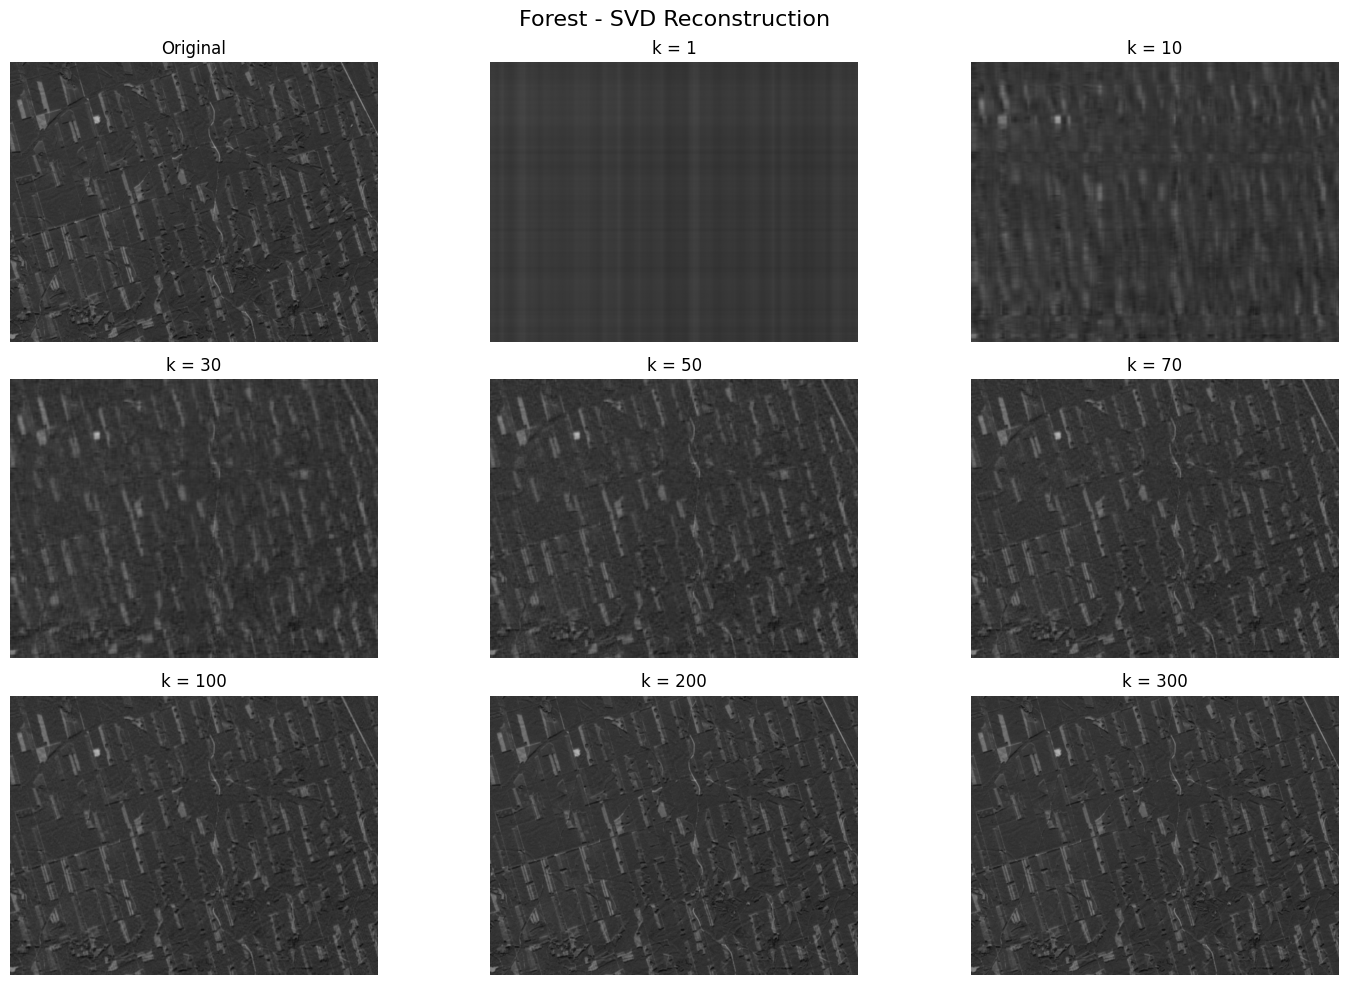

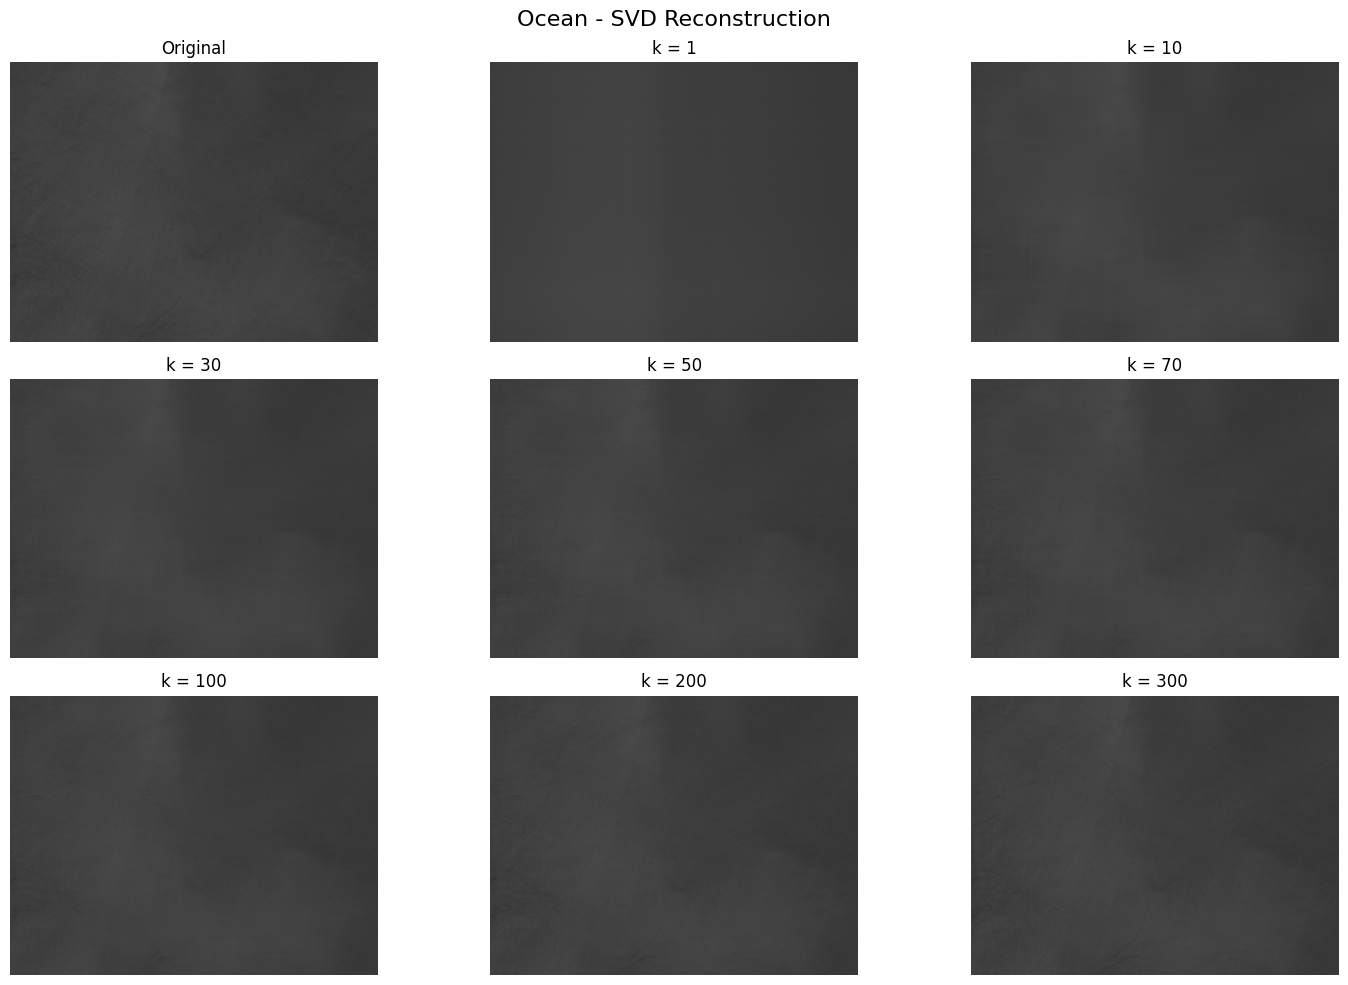

In [ ]:

k_values = [1, 10, 30, 50, 70, 100, 200, 300]

for name, result in svd_results.items():

    U = result["U"]
    sigma = result["sigma"]
    Vh = result["Vh"]

    fig, axes = plt.subplots(3, 3, figsize=(15, 10))
    axes = axes.flatten()

    axes[0].imshow(images[name], cmap='gray', vmin=0, vmax=255)
    axes[0].set_title("Original")

    for ax, k in zip(axes[1:], k_values):

        actual_k = min(k, len(sigma))

        reconstruction = (
            U[:, :actual_k] @
            np.diag(sigma[:actual_k]) @
            Vh[:actual_k, :]
        )

        ax.imshow(reconstruction, cmap='gray', vmin=0, vmax=255)
        ax.set_title(f"k = {actual_k}")

    for ax in axes:
        ax.axis('off')

    fig.suptitle(f"{name} - SVD Reconstruction", fontsize=16)
    plt.tight_layout()
    plt.show()


## Comparing reconstructions after removing the largest singular values

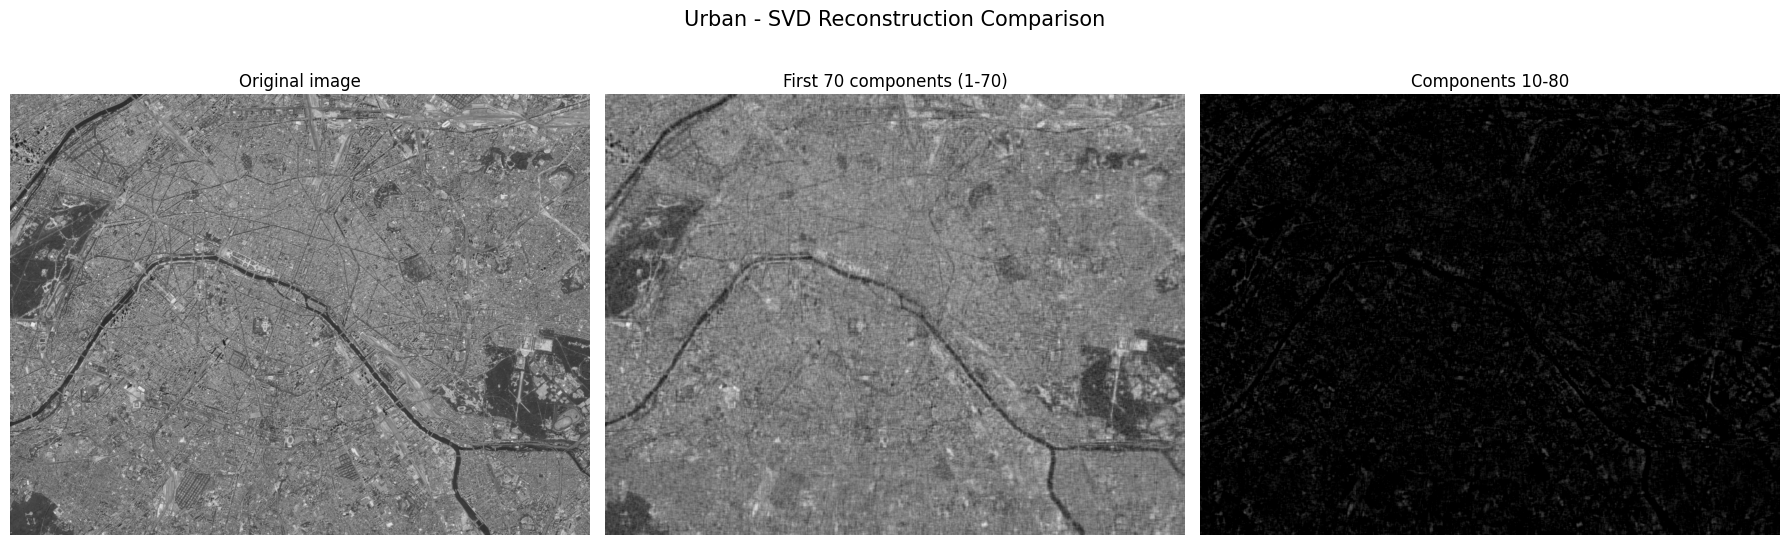

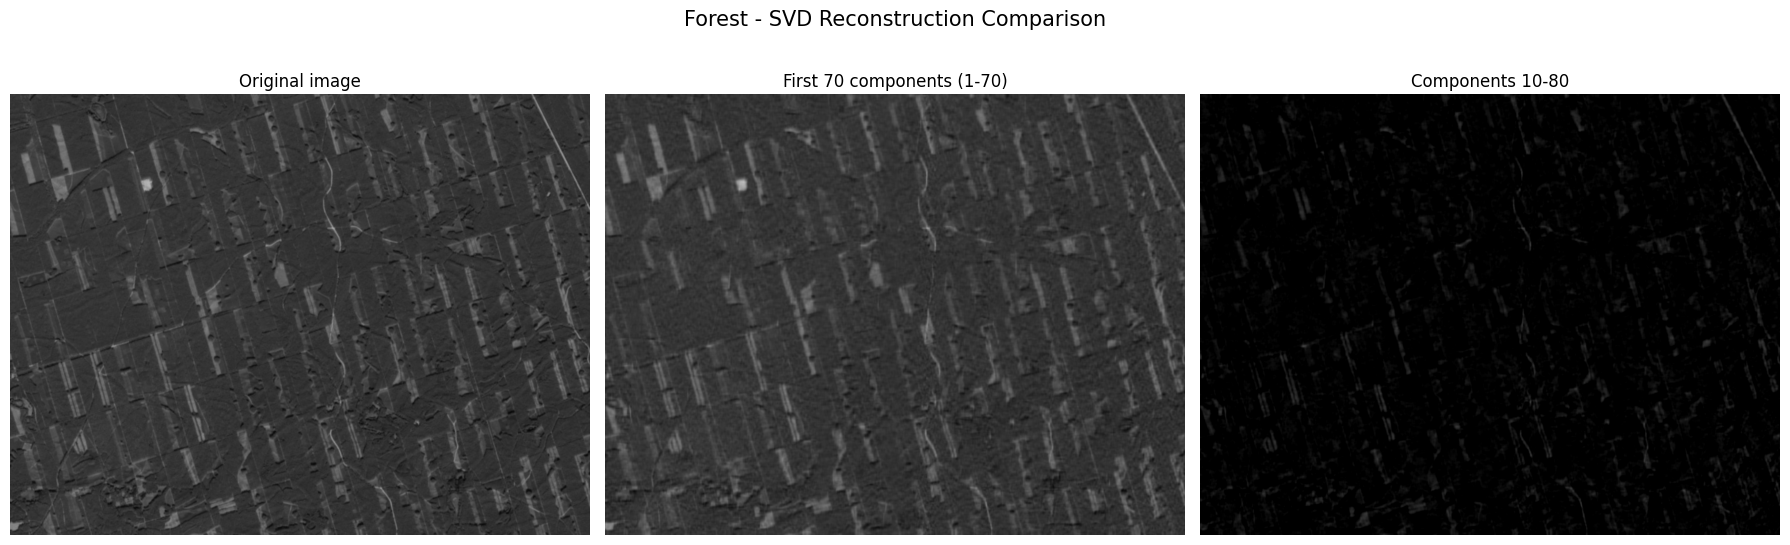

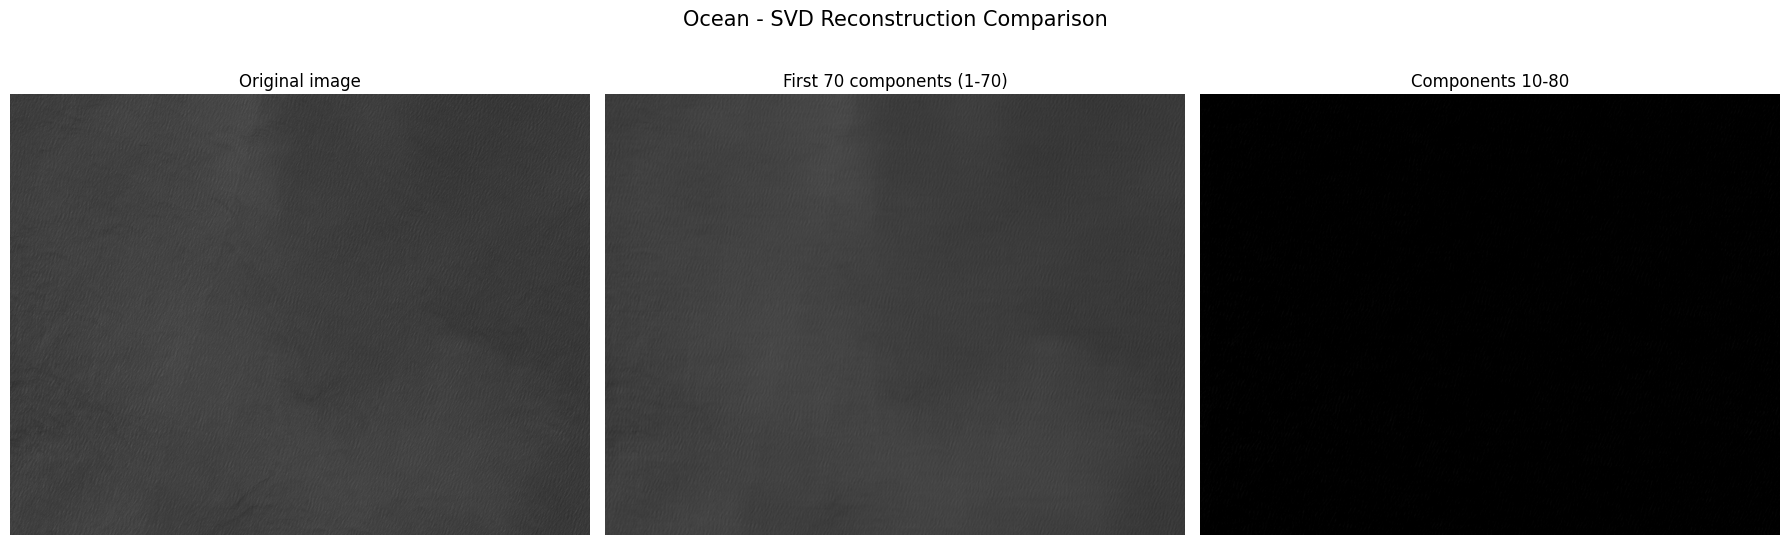

In [ ]:
k = 70

for name, result in svd_results.items():

    U = result["U"]
    sigma = result["sigma"]
    Vh = result["Vh"]

    if len(sigma) < k + 10:
        print(f"{name}: Not enough singular values for comparison.")
        continue

    #1-70)
    reconstruction_first = (
        U[:, :k] @
        np.diag(sigma[:k]) @
        Vh[:k, :]
    )

    #from 10th to 80th
    reconstruction_shifted = (
        U[:, 9:k+10] @
        np.diag(sigma[9:k+10]) @
        Vh[9:k+10, :]
    )

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    comparisons = [
        (images[name], "Original image"),
        (reconstruction_first, "First 70 components (1-70)"),
        (reconstruction_shifted, "Components 10-80")
    ]

    for ax, (img, title) in zip(axes, comparisons):
        ax.imshow(img, cmap='gray', vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis('off')

    fig.suptitle(f"{name} - SVD Reconstruction Comparison", fontsize=15)
    plt.tight_layout()
    plt.show()

### Observations & Answers (Based on Visual Comparison)

#### How many Eigen values are good enough?
Looking at the reconstructed images, about 50 to 70 components are visually good enough to get a very clear picture where you can easily recognize all the main shapes and details without noticeable blurriness.

#### If we use components 10 to 80 instead of 1 to 70, do we get better images?
No, the quality is much worse, the first 10 largest singular values contain the overall brightness, contrast, and basic layout of the image. Skipping them and starting from the 10th component results in an extremely dark, ghostly image showing only thin outlines and noise, completely losing the actual scene.

#### How do different terrains behave? (Forest vs. Urban vs. Ocean)
**Ocean:** This is the easiest terrain to compress. Because it is mostly flat water with very little detail, even at 10 to 30 components it looks virtually identical to the original image without any visual loss.

**Forest**: Contains repetitive tree patterns. It starts looking very close to the original at around 50 components, where the fine grain of the forest becomes clear.

**Urban:** This is the most challenging terrain because of sharp streets, buildings, and complex structures, while 70 components give a recognizable map, you can still spot slight blurriness compared to the original, meaning urban terrains benefit from even higher values (like 100+) to completely eliminate degradation.


Urban:
Components needed for 95% energy: 1
Components needed for 99% energy: 167


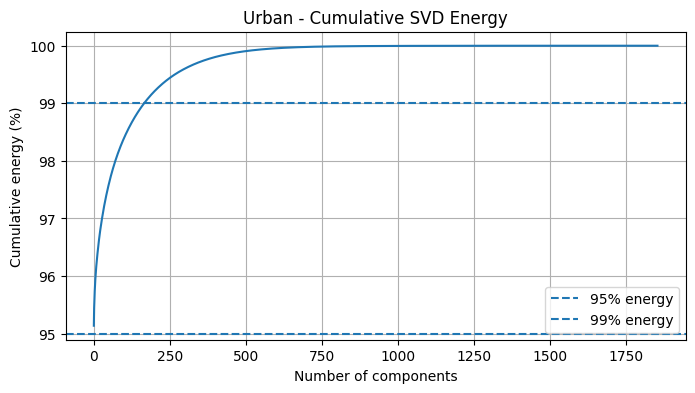


Forest:
Components needed for 95% energy: 2
Components needed for 99% energy: 55


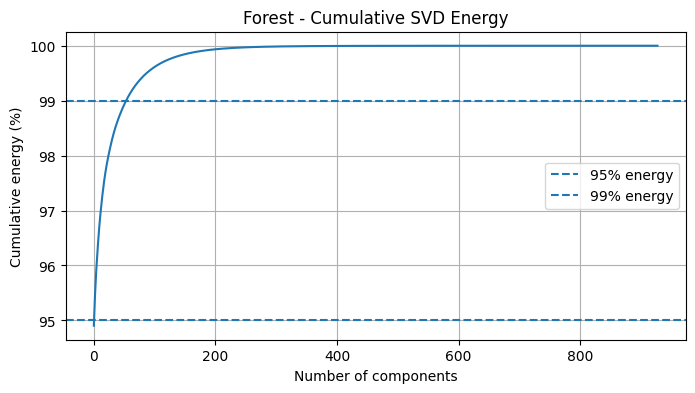


Ocean:
Components needed for 95% energy: 1
Components needed for 99% energy: 1


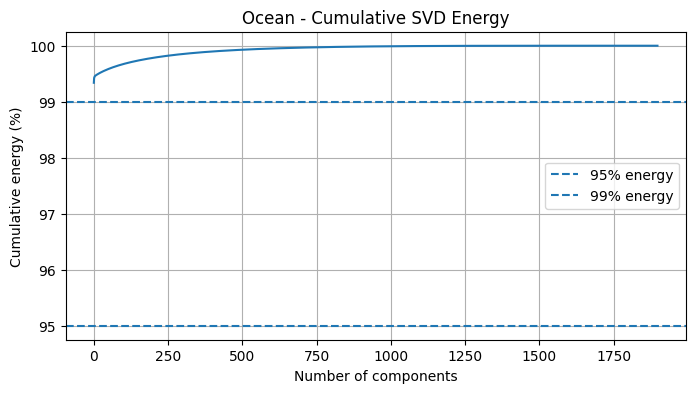

In [ ]:
for name, result in svd_results.items():

    sigma = result["sigma"]

    #cumulative energy
    energy = sigma**2
    cumulative_energy = np.cumsum(energy) / np.sum(energy)

    #number of components for 95% and 99% energy
    k_95 = np.searchsorted(cumulative_energy, 0.95) + 1
    k_99 = np.searchsorted(cumulative_energy, 0.99) + 1

    print(f"\n{name}:")
    print(f"Components needed for 95% energy: {k_95}")
    print(f"Components needed for 99% energy: {k_99}")

    plt.figure(figsize=(8, 4))
    plt.plot(cumulative_energy * 100)
    plt.axhline(95, linestyle='--', label='95% energy')
    plt.axhline(99, linestyle='--', label='99% energy')

    plt.xlabel("Number of components")
    plt.ylabel("Cumulative energy (%)")
    plt.title(f"{name} - Cumulative SVD Energy")
    plt.legend()
    plt.grid(True)
    plt.show()


In [ ]:
import pandas as pd

summary = []

for name, result in svd_results.items():

    sigma = result["sigma"]
    energy = sigma**2
    cumulative_energy = np.cumsum(energy) / np.sum(energy)

    k_95 = np.searchsorted(cumulative_energy, 0.95) + 1
    k_99 = np.searchsorted(cumulative_energy, 0.99) + 1

    summary.append({
        "Terrain": name,
        "Image size": str(images[name].shape),
        "Total components": len(sigma),
        "Components for 95% energy": k_95,
        "Components for 99% energy": k_99
    })

summary_df = pd.DataFrame(summary)
display(summary_df)


,Terrain,Image size,Total components,Components for 95% energy,Components for 99% energy
0,Urban,"(1856, 2442)",1856,1,167
1,Forest,"(928, 1221)",928,2,55
2,Ocean,"(1899, 2500)",1899,1,1


### SVD Compression Performance Analysis

Additionally, cmparing the singular value decay across our three landscape types gives us a clear look at how scene complexity impacts SVD compression efficiency:

* **Ocean (High Compression Efficiency):** Needs only 1 component to secure 99% of image energy, because open ocean scenes are highly uniform with low entropy, a single background intensity value captures almost the entire picture.
* **Forest (Moderate Compression Efficiency):** Needs 55 components for 99% energy - forest textures are more complex and detailed, yet highly repetitive, allowing SVD to compress the patterns efficiently.
* **Urban (Low Compression Efficiency):** Requires 167 components to capture 99% energy, the sharp boundaries make SVD work significantly harder to preserve detail.

Energy is a useful mathematical measure, but it doesnt guarantee that the reconstructed image will look identical to the original, thats why we also compared images visually.